# Convoluzione in 1 dimensione



Formula della convoluzione:

$$
(x * w) (t) = \int_{\mathbb{R}} x (a) w ( t - a) da
$$

Librerie necessarie:
- `pytorch` 
    - https://pytorch.org/
    - https://docs.pytorch.org/docs/stable/index.html
- `numpy`
- `matplotlib`
- `pandas`
- `sklearn`

Importiamo un dataset di segnali

In [1]:
import pandas as pd

df = pd.read_csv('./data/impulse_signals_dataset_noisy.csv')

print(f"Forma del dataset: {df.shape}")
print(f"Etichette: {df['label'].value_counts().sort_index().to_dict()}")
print(f"Prime righe del dataset:")
print(df.head())

Forma del dataset: (100, 101)
Etichette: {0: 50, 1: 50}
Prime righe del dataset:
   sample_0  sample_1  sample_2  sample_3  sample_4  sample_5  sample_6  \
0  0.533244  0.063765 -0.111172  0.233782 -0.388833 -0.451825 -0.124500   
1  0.680498 -0.273103 -0.082953 -0.016866  0.427883 -0.470229 -0.017530   
2 -0.605237 -0.096722  0.791618 -0.488681  0.474882 -0.379172  0.506545   
3 -0.378475 -0.104757 -0.132834 -0.307253 -0.054325  0.028585 -0.137793   
4 -0.283796 -0.177090  0.090724 -0.015698 -0.423678 -0.187335  0.294203   

   sample_7  sample_8  sample_9  ...  sample_91  sample_92  sample_93  \
0 -0.215139  0.865890  0.625630  ...   0.341346   0.063777   0.780611   
1  0.204740  0.060936  0.591921  ...   0.195613  -0.062478   0.016067   
2 -0.279370 -0.198860  0.528466  ...   0.615318   0.018300  -0.038567   
3 -0.418027  0.261175 -0.137493  ...  -0.254342   0.233732  -0.247300   
4  0.157897  0.069271 -0.455359  ...  -0.216296  -0.188830   0.495759   

   sample_94  sample_95  samp

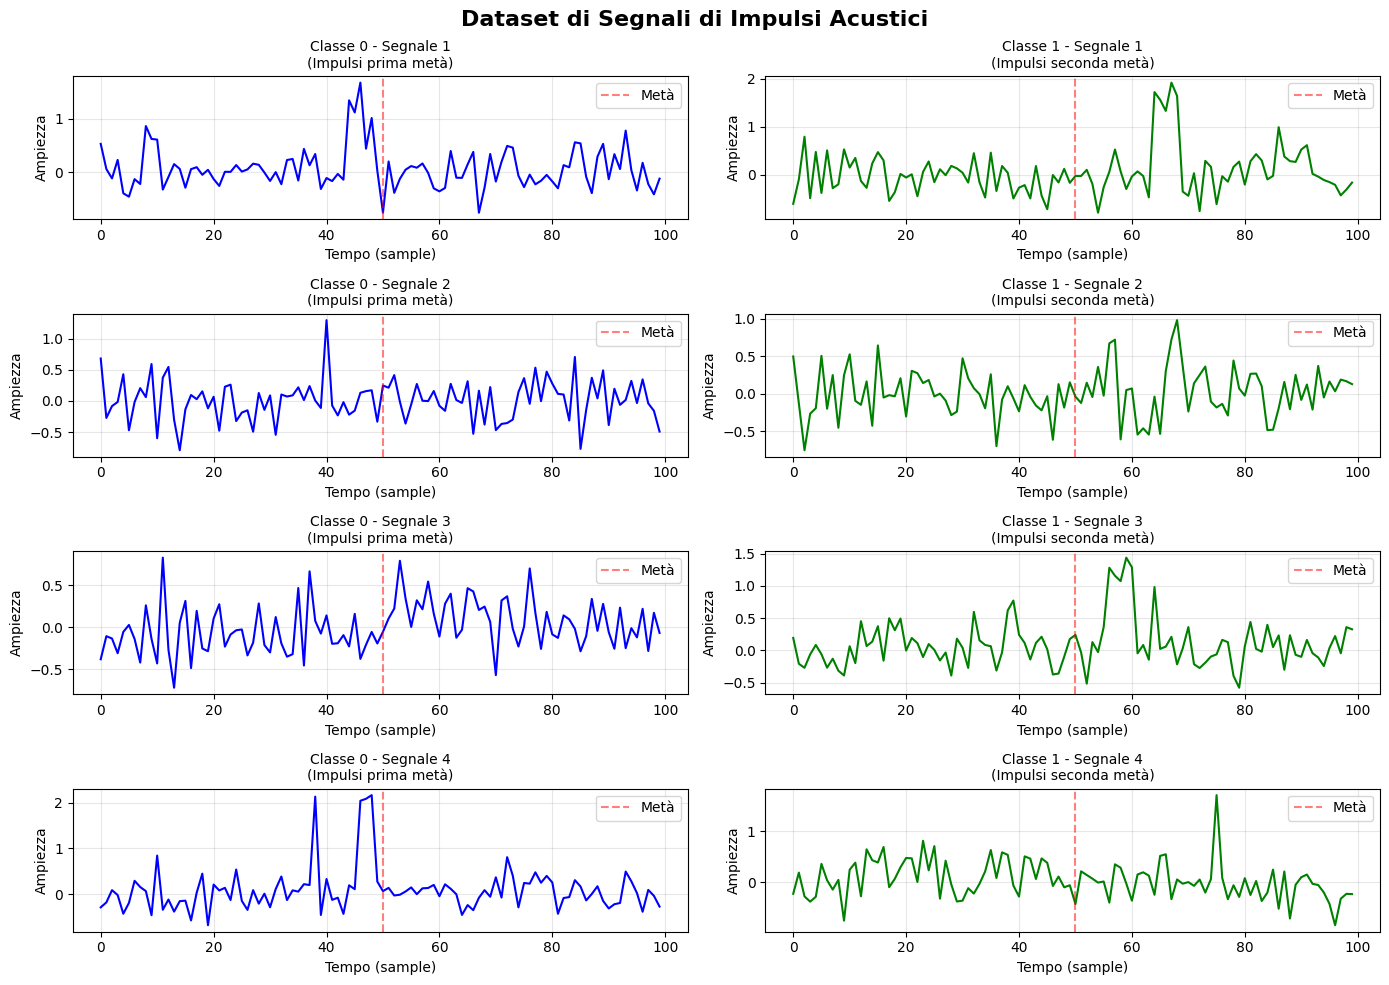

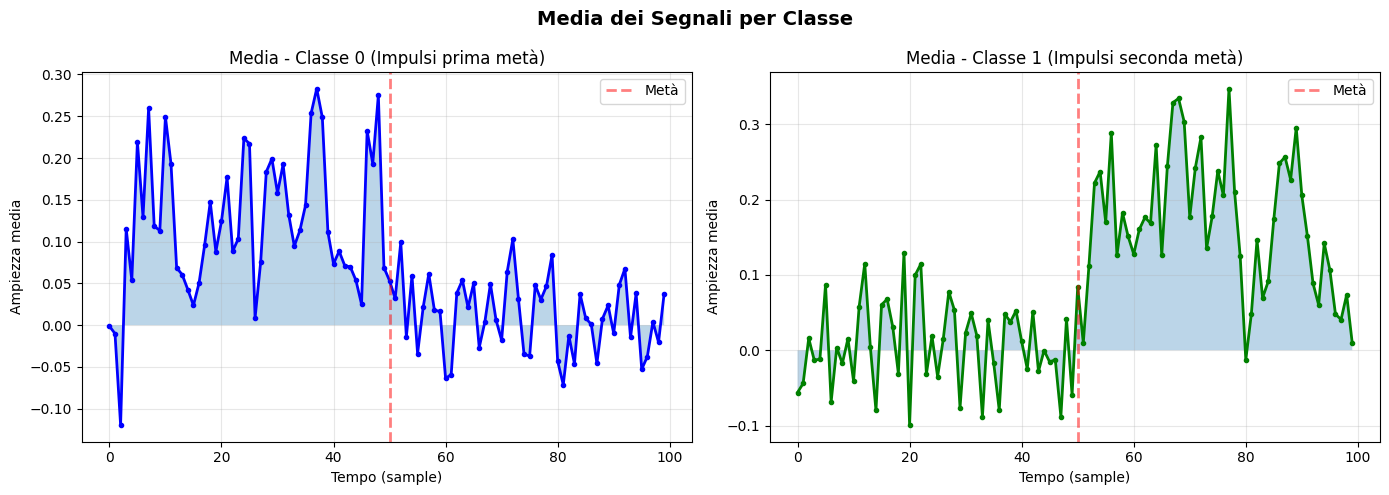

Statistiche del dataset:
Classe 0 - Media: 0.0680, Std: 0.4394
Classe 1 - Media: 0.0875, Std: 0.4532


In [2]:
import visualize_impulse_signals

### Creare un MLP per classificare i dati

L'MLP deve avere un solo strato nascosto, un input layer di 100 neuroni e un output layer con 2 uscite, una per classe.

In [3]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size=100, hidden_size=64, num_classes=2):
        super(MLP, self).__init__()

        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = self.fc1(x) # pre-attivazione

        x = torch.relu(x) # attivazione ReLU

        out = self.fc2(x) # secondo strato

        return out


model = MLP(input_size=100, hidden_size=64, num_classes=2)

Importare il dataset per l'uso con MLP

In [4]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split


X = df.drop('label', axis=1).values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = torch.FloatTensor(X_train)
y_train = torch.LongTensor(y_train)

X_test = torch.FloatTensor(X_test)
y_test = torch.LongTensor(y_test)

train_dataset = TensorDataset(X_train, y_train)

# Data loader, "genera dati" senza occupare spazio, basandosi su X_train e y_train
# batch_size, serve per velocizzare l'addestramento
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

# creazione dataset

Definire una loss e un ottimizzatore, poi addestrare l'MLP.

In [8]:
# ottimizzatore, discesa del gradiente

criterion = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.5)

epochs = 20

for epoch in range(epochs):
    for X_batch, y_batch in train_loader:
        
        # passo forward, scorciatoia per model.forward(X_batch)
        outputs = model(X_batch)

        # calcolo l'errore
        #loss = criterion(outputs, y_batch)

        y_batch_onehhot = torch.nn.functional.one_hot(y_batch, num_classes=2).float()
        loss = criterion(outputs, y_batch_onehhot)

        # algoritmo di back propagation 
        loss.backward()

        # azzeramento dei gradienti
        optimizer.zero_grad()
        
        # discesa del gradiente e aggiornamento dei pesi
        optimizer.step() # nuovi pesi = pesi - learning_rate * gradiente

    print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}')

with torch.no_grad():
    y_pred = model(X_test).argmax(dim=1)
    accuracy = (y_pred == y_test).float().mean()

    print(f'Accuracy: {accuracy.item():.4f}')



Epoch [1/20], Loss: 0.5832
Epoch [2/20], Loss: 0.5554
Epoch [3/20], Loss: 0.6090
Epoch [4/20], Loss: 0.5849
Epoch [5/20], Loss: 0.6013
Epoch [6/20], Loss: 0.5790
Epoch [7/20], Loss: 0.6217
Epoch [8/20], Loss: 0.5459
Epoch [9/20], Loss: 0.6036
Epoch [10/20], Loss: 0.5015
Epoch [11/20], Loss: 0.6039
Epoch [12/20], Loss: 0.5887
Epoch [13/20], Loss: 0.5775
Epoch [14/20], Loss: 0.6140
Epoch [15/20], Loss: 0.5735
Epoch [16/20], Loss: 0.5993
Epoch [17/20], Loss: 0.5746
Epoch [18/20], Loss: 0.5920
Epoch [19/20], Loss: 0.6660
Epoch [20/20], Loss: 0.5605
Accuracy: 0.3000


### Convoluzione dei segnali in ingresso

Definire due kernel di dimensione 5 per la convoluzione: filtro di media e filtro gaussiano.

Applicare i due kernel a 5 esempi di segnali in ingresso presenti nel training set, e visualizzare i risultati.

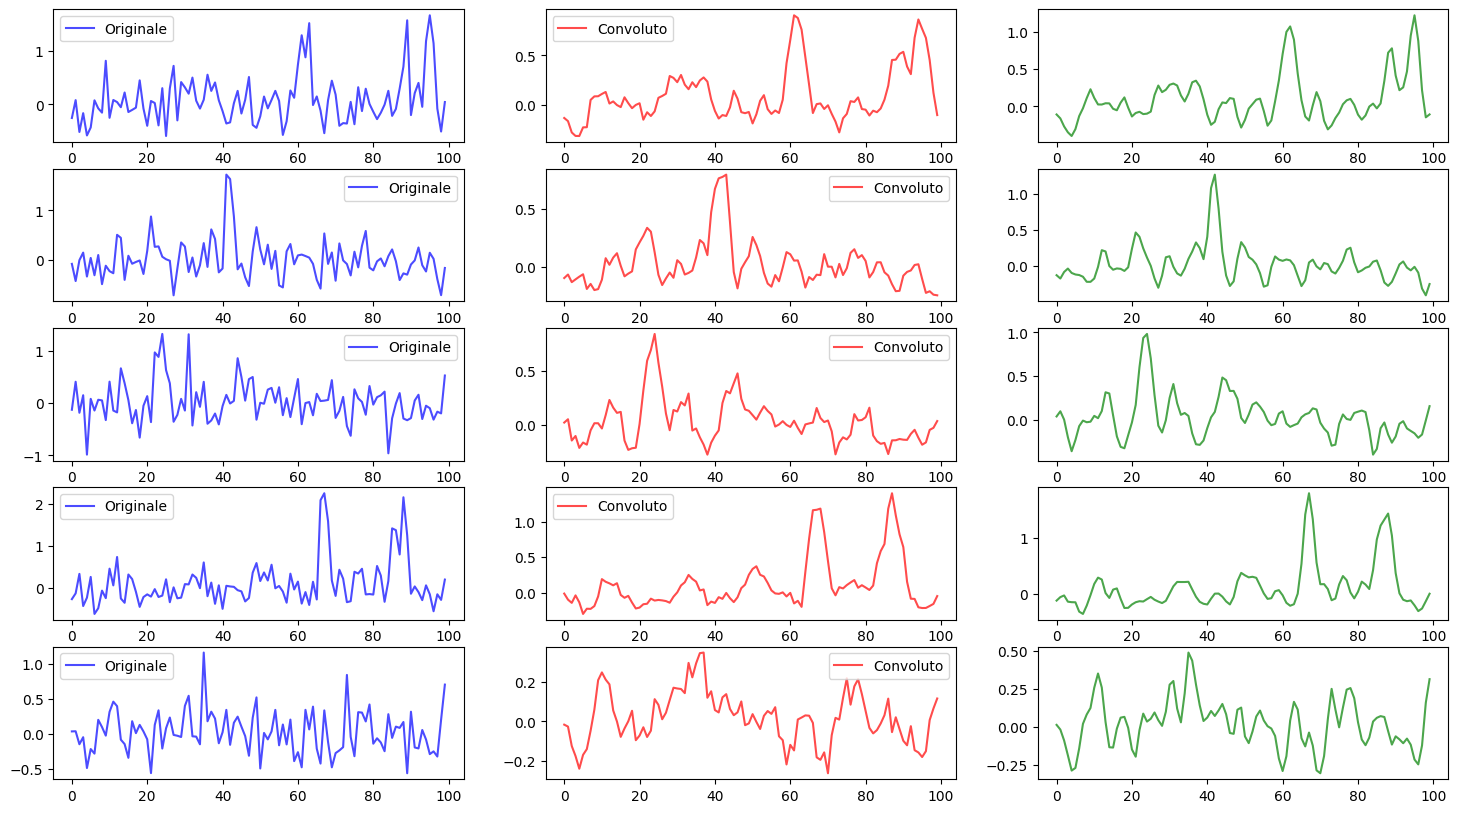

In [9]:
import numpy as np

import matplotlib.pyplot as plt

    

kernel = np.ones(5) / 5

x = np.linspace(-2, 2, 5)

kernel_gaussian = np.exp(-(x ** 2) / 2)
kernel_gaussian /= kernel_gaussian.sum()

def convolve1D(signal, kernel):
    signal_length = len(signal)
    kernel_length = len(kernel)

    output_length = signal_length - kernel_length + 1

    output = np.zeros(output_length)

    for i in range(output_length):
        output[i] = np.sum(signal[i:i+kernel_length] * kernel)

    return output


signal = X_train[0].numpy()

#signal_convolved = np.convolve(signal, kernel, mode='same')
#signal_convolved = np.convolve(signal, kernel_gaussian, mode='same')

fig, axes = plt.subplots(5, 3, figsize=(18, 10))

for i in range(5):
    signal = X_train[i].numpy()
    signal_convolved = np.convolve(signal, kernel, mode='same')
    signal_convolved_gaussian = np.convolve(signal, kernel_gaussian, mode='same')

    
    axes[i, 0].plot(signal, label='Originale', color='blue', alpha=0.7)
    axes[i, 0].legend()

    axes[i, 1].plot(signal_convolved, label='Convoluto', color='red', alpha=0.7)
    axes[i, 1].legend()

    axes[i, 2].plot(signal_convolved_gaussian, label='Convoluto Gaussiano', color='Green', alpha=0.7)


signal_convolved = convolve1D(signal, kernel)
signal_convolved_gaussian = convolve1D(signal, kernel_gaussian)


Effettuare la convoluzione con kernel di media su tutto il dataset di training e di testing, poi addestrare lo stesso MLP di prima sui nuovi dataset.

In [8]:
# Pre-processing

kernel = np.ones(100) / 100

for i in range(100):
    signal_train = convolve1D(X_train[i].numpy(), kernel)
    signal_test = convolve1D(X_test[i].numpy(), kernel)

# recupera lezione del 15/04/2026, ultimi 10 minuti



IndexError: index 20 is out of bounds for dimension 0 with size 20

Effettuare la convoluzione con kernel gaussiano su tutto il dataset di training e di testing, poi addestrare lo stesso MLP di prima sui nuovi dataset.

### Rete convoluzionale

Invece di modificare i dati con il pre-processing, è possibile chiedere alla rete di applicare una convoluzione 1D sui dati in ingresso. 

Questo si fa utilizzando un layer convolutivo, con 100 neuroni in ingresso (il segnale): bisogna poi indicare quanti kernel si vogliono applicare (output channels) e qual è la loro dimensione (kernel size). 

Infine, si procede come al solito con l'implementazione di layer fully-connected.

Creare la rete convoluzionale.

In [10]:
class Conv1DMLP(nn.Module):
    def __init__(self, input_size, conv_out_channels, kernel_size, hidden_size, num_classes):
        super(Conv1DMLP, self).__init__()

        self.conv1 = nn.Conv1d(in_channels=1, out_channels=conv_out_channels,
                                kernel_size=kernel_size, padding=kernel_size//2)

        self.fc1 = nn.Linear(input_size * conv_out_channels, hidden_size)
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.unsqueeze(1)

        x = self.conv1(x)

        x = torch.relu(x)

        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = torch.relu(x)
        x = self.fc2(x)

        return x

        
        

model_conv1d = Conv1DMLP(input_size=100, conv_out_channels=32, kernel_size=5, hidden_size=64, num_classes=2)

Addestrare la rete convoluzionale con MSE loss e SGD.

In [11]:
np.random.seed(42)
torch.manual_seed(42)

criterion_conv1d = nn.MSELoss()
optimizer_conv1d = torch.optim.SGD(model_conv1d.parameters(), lr=0.01)

train_dataset_conv1d = TensorDataset(X_train, y_train)
train_loader_conv1d = DataLoader(train_dataset_conv1d, batch_size=8, shuffle=True)

epochs = 10 

for epoch in range(epochs):
    for X_batch, y_batch in train_loader_conv1d:

        optimizer_conv1d.zero_grad()

        outputs = model_conv1d(X_batch) # passo forwards

        y_batch_onehot_conv1d = torch.nn.functional.one_hot(y_batch, num_classes=2).float()
        loss = criterion_conv1d(outputs, y_batch_onehot_conv1d)

        loss.backward() # back propagation

        optimizer_conv1d.step() # discesa del gradiente (aggiornamento dei pesi)

    print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}')



Epoch [1/10], Loss: 0.2447
Epoch [2/10], Loss: 0.2259
Epoch [3/10], Loss: 0.1852
Epoch [4/10], Loss: 0.2196
Epoch [5/10], Loss: 0.1253
Epoch [6/10], Loss: 0.1202
Epoch [7/10], Loss: 0.1261
Epoch [8/10], Loss: 0.0972
Epoch [9/10], Loss: 0.1556
Epoch [10/10], Loss: 0.0642


Visualizzare i pesi della rete: è utile per capire quali kernel sono stati applicati all'ingresso.

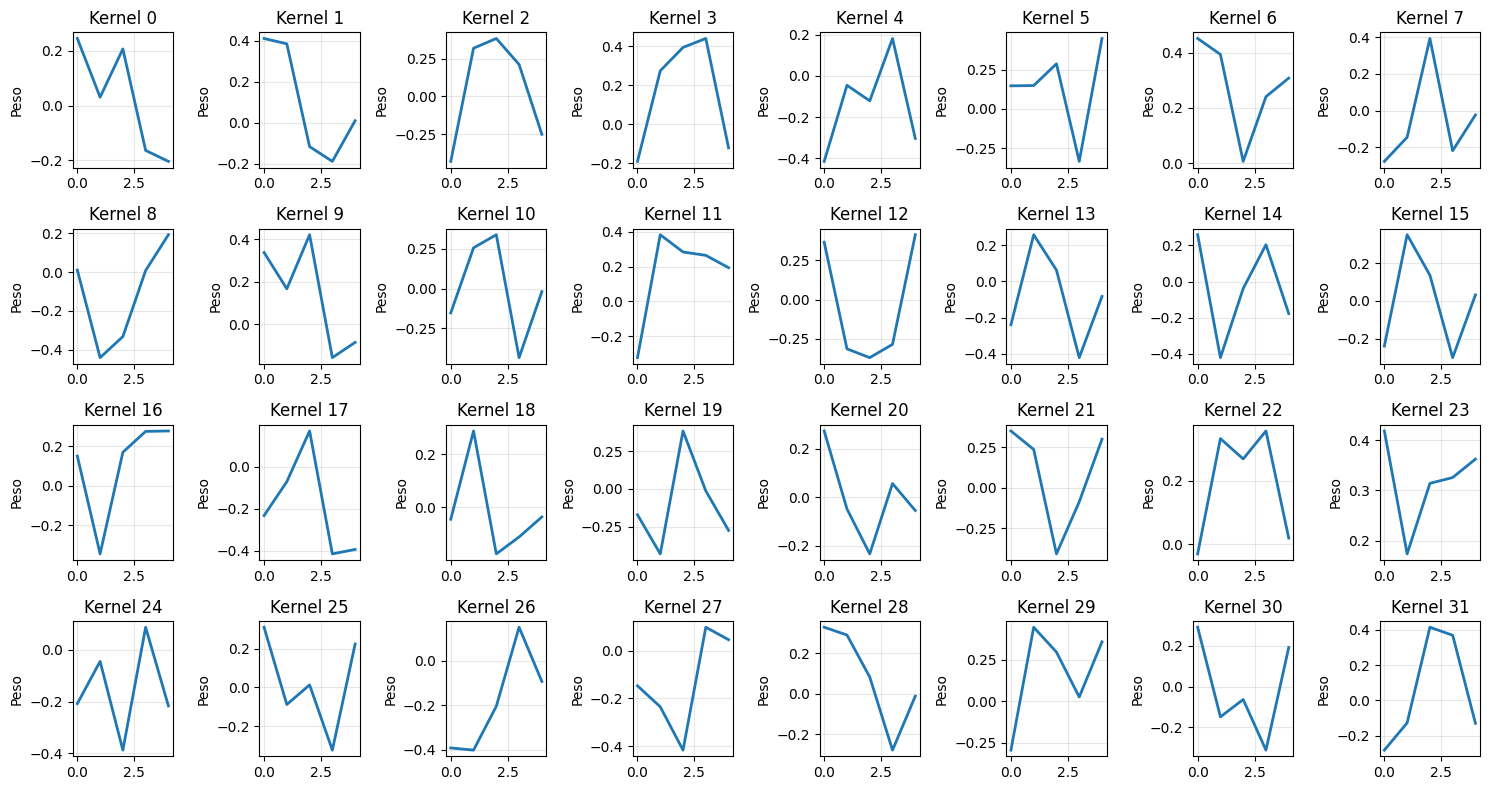

In [12]:
conv1d_weights = model_conv1d.conv1.weight.data.cpu().numpy()

fig, axes = plt.subplots(4, 8, figsize=(15, 8))
axes = axes.flatten()

for i in range(min(32, conv1d_weights.shape[0])):
    kernel = conv1d_weights[i, 0, :]
    axes[i].plot(kernel, linewidth=2)
    axes[i].set_title(f'Kernel {i}')
    axes[i].grid(True, alpha=0.3)
    axes[i].set_ylabel('Peso')

plt.tight_layout()
plt.show()